# Chapter 9: Contextual Bandits: The Right Message for Each Learner

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Contextual Bandits: The Right Message for Each Learner](https://books.sugiv.fyi/lift/contextual-bandits.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import context as C, parlo, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


SEED = 1
one_size = C.simulate(C.thompson_one_size, seed=SEED)
per_segment = C.simulate(C.thompson_per_segment, seed=SEED)
linear = C.simulate(C.linear_thompson(), linear=True, seed=SEED)

lost = lambda r: r.regret[:, -1].mean()
daily = lambda r: r.lessons[:, -5:].mean()
glue_num("one_lost", lost(one_size))
glue_num("lin_lost", lost(linear))
glue_num("one_daily", daily(one_size))
glue_num("lin_daily", daily(linear))
glue_num("oracle_daily", 500 * C.RATES.max(axis=1).mean())
glue_num("lift_pct", 100 * (daily(linear) / daily(one_size) - 1))

Here's the finding first. The bandits in Chapters 7 and 8 look for **one** best message for everyone. Parlo's learners aren't all the same, though: beginners respond to a friendly note from Juno, advanced learners to a progress recap, and long streaks to a streak warning. A bandit that ignores this settles at about **54 lessons per 500 reminders**. A **contextual bandit** that takes each learner's level, streak and time of day into account reaches **68**. That's **26% more lessons** from the same reminders, close to the 71 a perfect oracle would get.

The second half of the chapter answers two questions every team hits next:

- **Would a new policy have done better?** Off-policy evaluation answers that from logs you already have, before you ship it.
- **What about sequences?** A journey of several messages has thousands of possible orderings. We can't test them all, so how do we choose?

## One size fits nobody

Each learner has four pieces of context: **level** (beginner, intermediate, advanced), **streak** (none, short, long), **time** of the reminder (morning or evening) and **phone** (iOS or Android). That's 36 combinations, or segments. Here's the true lesson rate for each message, averaged over time and phone:

In [3]:
seg = pd.DataFrame(C.SEGMENTS, columns=["level", "streak", "time", "phone"])
for col, values in C.FEATURES.items():
    seg[col] = seg[col].map(dict(enumerate(values)))
rates = pd.concat([seg, pd.DataFrame(C.RATES, columns=C.MESSAGES)], axis=1)
table = rates.groupby(["level", "streak"], sort=False)[C.MESSAGES].mean()
table["best"] = table[C.MESSAGES].idxmax(axis=1)
table

Plain nudge  Streak at risk  Juno says hi  \
level        streak                                              
beginner     none          0.095           0.055         0.145   
             short         0.095           0.105         0.145   
             long          0.095           0.155         0.145   
intermediate none          0.095           0.055         0.115   
             short         0.095           0.105         0.115   
             long          0.095           0.155         0.115   
advanced     none          0.095           0.055         0.075   
             short         0.095           0.105         0.075   
             long          0.095           0.155         0.075   

                     Progress recap            best  
level        streak                                  
beginner     none             0.075    Juno says hi  
             short            0.075    Juno says hi  
             long             0.075  Streak at risk  
intermediate none             0.105    Juno says hi  
             short            0.105    Juno says hi  
             long             0.105  Streak at risk  
advanced     none             0.145  Progress recap  
             short            0.145  Progress recap  
             long             0.145  Streak at risk

In [4]:
glue_num("best_single", C.RATES.mean(axis=0).max() * 100)
glue_num("best_each", C.RATES.max(axis=1).mean() * 100)

No message wins everywhere. The best *single* message, "Juno says hi", averages 11.2% across all learners. Sending each learner their own best message averages 14.2%. That gap is what context is worth. And the phone column doesn't matter at all. I put it there on purpose, because real data is full of features that don't matter.

## Three ways to use context

**1. Ignore it.** One Thompson bandit for everyone, as in Chapter 7. It learns fast, but it can only find the best average message.

**2. One bandit per segment.** Run a separate Thompson bandit for each of the 36 segments. It can find each segment's best message, but each bandit only sees 1/36 of the traffic, so it learns slowly. It also splits iOS and Android apart for no reason.

**3. Linear Thompson sampling.** Predict each message's lesson rate from the learner's features with a small linear model, one per message, and use Thompson sampling on the model's *weights*. What it learns about beginners in the evening helps with beginners in the morning, because they share the "beginner" weight. This is called *sharing strength*.

In [5]:
runs = {"Ignore context": one_size, "One bandit per segment": per_segment,
        "Linear Thompson": linear}
pd.DataFrame({
    "lessons lost over 30 days": {k: lost(r) for k, r in runs.items()},
    "lessons per 500 reminders (last 5 days)": {k: daily(r) for k, r in runs.items()},
}).round(1)

,lessons lost over 30 days,lessons per 500 reminders (last 5 days)
Ignore context,501.3,54.3
One bandit per segment,358.3,62.0
Linear Thompson,166.2,68.2


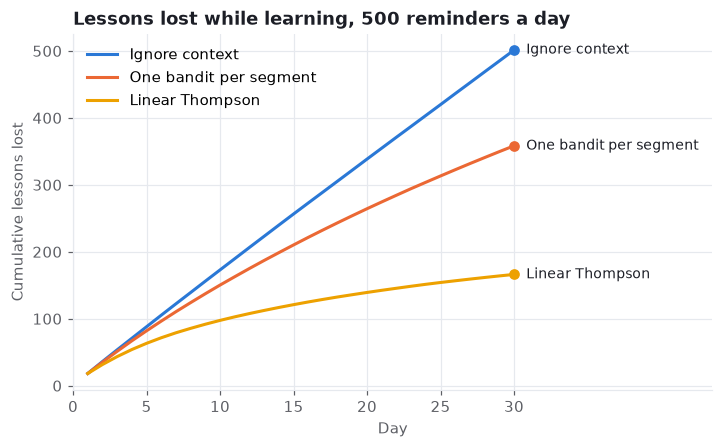

In [6]:
colours = {"Ignore context": style.SERIES[0], "One bandit per segment": style.SERIES[1],
           "Linear Thompson": style.SERIES[3]}
fig, ax = plt.subplots()
for name, r in runs.items():
    y = r.regret.mean(axis=0)
    x = np.arange(1, len(y) + 1)
    ax.plot(x, y, color=colours[name], label=name)
    style.label_line_end(ax, x[-1], y[-1], name, colours[name])
ax.set(title="Lessons lost while learning, 500 reminders a day",
       xlabel="Day", ylabel="Cumulative lessons lost")
ax.set_xlim(0, 30 * 1.45)
ax.set_xticks(range(0, 31, 5))
ax.legend(loc="upper left")
plt.show()

The per-segment bandit beats ignoring context, but it spends a long time learning 36 separate answers from thin data. Linear Thompson gets most of the way there within a few days, because each reminder teaches it something about every segment that shares a feature with the learner.

Here's what the linear bandit ends up sending, by level and streak, over the last five days:

In [7]:
picks = pd.concat([seg, pd.DataFrame(linear.picks, columns=C.MESSAGES)], axis=1)
picks.groupby(["level", "streak"], sort=False)[C.MESSAGES].mean().style.format("{:.0%}")

Compare it with the "best" column in the first table: it has learned the structure. Long streaks get the streak warning, beginners get Juno, and advanced learners get the recap. Where two messages are within a point of each other, as for intermediate learners without a long streak, or beginners and advanced learners with a long one, it still spreads its sends. That isn't indecision. Choosing between near-ties costs almost nothing, so it keeps exploring in case it has them the wrong way round.

<details>
<summary><b>Under the hood: linear Thompson sampling</b></summary>

For each message $a$, model the lesson rate as $x^\top w_a$, where $x$ is the learner's feature vector (an intercept plus one-hot columns). With noise variance $\sigma^2$ and a Gaussian prior $w_a \sim N(0, \sigma^2\lambda^{-1} I)$, after seeing features $X_a$ and outcomes $y_a$ for message $a$, the posterior is

$$w_a \sim N\big(A_a^{-1} b_a,\ \sigma^2 A_a^{-1}\big), \quad A_a = \lambda I + X_a^\top X_a, \quad b_a = X_a^\top y_a.$$

For each learner, draw one $\tilde w_a$ per message from its posterior and send $\arg\max_a x^\top \tilde w_a$. Agrawal and Goyal (Agrawal and Goyal, 2013) give regret guarantees. The deterministic cousin, LinUCB, became famous for news recommendation at Yahoo (Li et al., 2010). In `lift/sim/context.py` the whole thing is about 15 lines of numpy.

</details>

> **Note**
>
> A linear model is a choice, not a law. It works here because the true effects are roughly additive: being a beginner helps Juno's message whatever the time of day. If effects interact strongly, add interaction features, or swap the linear model for a small tree ensemble or neural network with an uncertainty estimate. The Thompson idea stays the same: sample a plausible model, act greedily on the sample.

## Would the new policy have done better?

Before Parlo ever ran a contextual bandit, its production rule was simple: send "Juno says hi" to everyone, but pick a random message 10% of the time. Someone now proposes a smarter rule, "send each segment its best message". Can we tell whether it would win, using only the logs from the old rule, without shipping anything?

This is **off-policy evaluation** (OPE): estimating the value of a *target* policy from data collected by a different *logging* policy.

In [8]:
logging = np.full((C.N_SEG, C.K), 0.1 / C.K)
logging[:, C.MESSAGES.index("Juno says hi")] += 0.9          # Juno 92.5%, others 2.5% each

target = np.zeros((C.N_SEG, C.K))
target[np.arange(C.N_SEG), C.RATES.argmax(axis=1)] = 1        # each segment's best message

print(f"true value of the old rule: {C.true_value(logging):.4f}")
print(f"true value of the new rule: {C.true_value(target):.4f}")

true value of the old rule: 0.1110
true value of the new rule: 0.1417


In real life we don't know those true values. That's the point. All we have is a log: for each send, the learner's segment, the message sent, whether a lesson followed, and, crucially, **the probability the old rule had of sending that message** (its *propensity*). Here are five ways to estimate the new rule's value from 20,000 logged sends, each repeated on 200 fresh logs so we can see how much the estimates bounce around:

In [9]:
rng = np.random.default_rng(0)
estimators = {
    "Logged average": lambda log, t: log.reward.mean(),
    "Direct method (model)": C.direct_method,
    "IPS": C.ips,
    "Self-normalised IPS": C.snips,
    "Doubly robust": C.doubly_robust,
}
est = {name: [] for name in estimators}
for _ in range(200):
    log = C.log_from(logging, 20_000, rng)
    for name, f in estimators.items():
        est[name].append(f(log, target))

truth = C.true_value(target)
pd.DataFrame({
    "average estimate": {k: np.mean(v) for k, v in est.items()},
    "bias": {k: np.mean(v) - truth for k, v in est.items()},
    "spread (sd)": {k: np.std(v) for k, v in est.items()},
}).round(4)

,average estimate,bias,spread (sd)
Logged average,0.111,-0.031,0.002
Direct method (model),0.136,-0.006,0.010
IPS,0.140,-0.002,0.012
Self-normalised IPS,0.140,-0.002,0.011
Doubly robust,0.139,-0.002,0.011


In [10]:
glue_num("truth_pct", 100 * truth)
glue_num("old_pct", 100 * C.true_value(logging))
glue_num("ips_pct", 100 * np.mean(est["IPS"]))
glue_num("dm_pct", 100 * np.mean(est["Direct method (model)"]))

What each one does, and what happened:

- **Logged average** just averages the outcomes in the log. That's the value of the *old* rule (11.1%), so it can't say anything about the new one. Surprisingly often, this is what a dashboard shows.
- **Direct method:** fit a model of the lesson rate for each segment and message, then ask the model what the new rule would get. It's stable, but it's only as good as the model. Here some segment-message pairs have only a handful of logged sends, the model shrinks them towards an average, and it comes out biased low (about 13.6% against a truth of 14.2%).
- **IPS (inverse propensity scoring):** keep only the logged sends where the old rule happened to do what the new rule would do, and up-weight each by one over the old rule's probability of having done it. A message the old rule sent only 2.5% of the time counts 40 times. It's unbiased (about 14.0%), but it's noisy, because a few heavily weighted sends move it a lot.
- **Self-normalised IPS** divides by the total weight instead of the number of sends. It's slightly biased in theory, usually less noisy in practice.
- **Doubly robust** starts from the model's prediction and adds an IPS correction for the model's mistakes. If either the model or the propensities are right, it's unbiased. With a good model it's also much less noisy than IPS. Here the model is weak, so the gain is small. That's the honest lesson: doubly robust is a safety net, not magic (Dud\'ik et al., 2011).

IPS, SNIPS and doubly robust all agree that the new rule would win, at about 14% against 11%. The logged average can't see it at all.

### OPE only works if you explored

IPS divides by the logging propensity. If the old rule *never* sent a message to a segment, there's nothing to reweight, and no amount of statistics can tell you what would have happened. The less you explored, the noisier OPE gets:

In [11]:
rows = []
for explore in [0.2, 0.1, 0.02]:
    logp = np.full((C.N_SEG, C.K), explore / C.K)
    logp[:, C.MESSAGES.index("Juno says hi")] += 1 - explore
    vals = [C.ips(C.log_from(logp, 20_000, rng), target) for _ in range(200)]
    rows.append({"exploration": f"{explore:.0%}", "IPS spread (sd)": np.std(vals),
                 "largest weight": 1 / (explore / C.K)})
pd.DataFrame(rows).set_index("exploration").round(4)

,IPS spread (sd),largest weight
exploration,,
20%,0.010,20.0
10%,0.013,40.0
2%,0.028,200.0


Two rules follow, and they're the most practical advice in this chapter:

1. **Always log the propensity.** Record the probability your system had of choosing what it chose, at the moment it chose it. You can't reconstruct it later. Thompson sampling doesn't give it to you in closed form, so estimate it at decision time by drawing a few hundred extra samples and counting how often each arm wins.
2. **Never set exploration to zero.** A few percent of randomness is what makes every future policy evaluable from your logs.

<details>
<summary><b>Under the hood: the three estimators</b></summary>

Let $\mu(a \mid x)$ be the logging policy, $\pi(a \mid x)$ the target policy, and $(x_i, a_i, r_i)$ the log, with $w_i = \pi(a_i \mid x_i)/\mu(a_i \mid x_i)$.

$$\hat V_{\text{IPS}} = \frac1n \sum_i w_i r_i, \qquad
\hat V_{\text{DM}} = \frac1n \sum_i \sum_a \pi(a \mid x_i)\, \hat q(x_i, a),$$

$$\hat V_{\text{DR}} = \frac1n \sum_i \Big[\sum_a \pi(a \mid x_i)\, \hat q(x_i, a) + w_i \big(r_i - \hat q(x_i, a_i)\big)\Big].$$

IPS is unbiased when $\mu > 0$ wherever $\pi > 0$. DR is unbiased if either $\hat q$ or $\mu$ is correct, and its variance depends on how wrong $\hat q$ is. Wager (Wager, 2026) treats these estimators as the policy-evaluation side of causal inference, which is exactly where Part III of this book picks them up again.

</details>

## Juno: a contextual router

The agent version of a contextual bandit is an **LLM router**: pick a model per request, based on what the request is. Juno's lessons come in three kinds, and the models' completion rates differ by kind:

In [12]:
tasks = pd.DataFrame({
    "large":  {"Vocabulary drill": 0.90, "Grammar explanation": 0.80, "Free conversation": 0.82},
    "medium": {"Vocabulary drill": 0.89, "Grammar explanation": 0.76, "Free conversation": 0.62},
    "small":  {"Vocabulary drill": 0.88, "Grammar explanation": 0.62, "Free conversation": 0.45},
})
cost = pd.Series({m.name: m.cost for m in parlo.JUNO_MODELS})
net = tasks * parlo.LESSON_VALUE - cost          # dollars of net value per lesson
net.assign(best=net.idxmax(axis=1))

,large,medium,small,best
Vocabulary drill,0.070,0.083,0.087,small
Grammar explanation,0.060,0.070,0.061,medium
Free conversation,0.062,0.056,0.044,large


In [13]:
single = net.mean().max()
per_task = net.max(axis=1).mean()
glue_num("router_gain", 1000 * (per_task - single))
glue_num("router_pct", 100 * (per_task / single - 1))

The cheap model is perfectly good at drills, the medium one handles grammar, and only the large model holds a conversation. Routing per task is worth about **$3 per 1,000 lessons** over the best single model, or 5% more net value, with nobody hand-writing rules. The context here is the task type. In practice it can also include the learner's level, the language pair, or features of the prompt itself. Everything in this chapter applies: share strength with a model when contexts are many, log propensities, keep some exploration, and evaluate a new router offline before you ship it.

## From orderings to steps

Back to journeys. Parlo wants to send three reminders over three days, picking three different messages out of four. That's $4 \times 3 \times 2 = 24$ orderings. The order matters in this world: Juno's invitation works much better the day after a progress recap, because the learner has just been reminded how far they've come.

There are two ways to frame it as a bandit:

- **Orderings as arms.** 24 arms, reward is the total number of lessons over the journey. It's correct, but it learns slowly, and it explodes: seven emails would be 5,040 arms.
- **Step by step.** At each step, pick the next message given the step number and the previous message. That's a small contextual bandit, and every send teaches it something. But it's **myopic**: each step maximises *its own* lesson rate, so it never discovers that a lower-scoring recap today sets up a big win tomorrow.

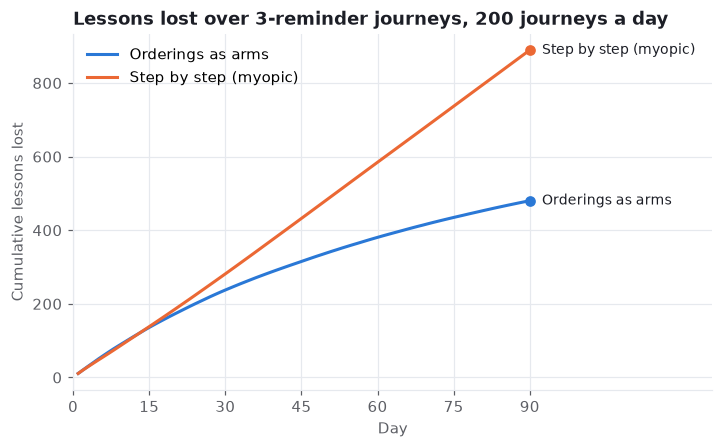

In [14]:
days = 90
as_arms = C.journey_orderings_as_arms(days=days, seed=SEED)
by_step = C.journey_step_by_step(days=days, seed=SEED)

fig, ax = plt.subplots()
for name, r, c in [("Orderings as arms", as_arms, style.SERIES[0]),
                   ("Step by step (myopic)", by_step, style.SERIES[1])]:
    y = r.mean(axis=0)
    x = np.arange(1, days + 1)
    ax.plot(x, y, color=c, label=name)
    style.label_line_end(ax, x[-1], y[-1], name, c)
ax.set(title="Lessons lost over 3-reminder journeys, 200 journeys a day",
       xlabel="Day", ylabel="Cumulative lessons lost")
ax.set_xlim(0, days * 1.4)
ax.set_xticks(range(0, days + 1, 15))
ax.legend(loc="upper left")
plt.show()

In [15]:
glue_num("step_daily", (by_step[:, -1] - by_step[:, -11]).mean() / 10)
glue_num("arms_daily", (as_arms[:, -1] - as_arms[:, -11]).mean() / 10)

At first the two are close, because the step-by-step bandit learns each step quickly. Then they diverge. The step-by-step bandit settles on "Juno first", the best *single* message, and keeps losing about 10 lessons a day forever. Treating orderings as arms learns slowly but finds the recap-then-Juno journey, and its losses shrink towards zero (about 3 a day by the end).

That's the trade-off behind every journey optimiser, including the Better Mortgage case from Chapter 7 (JustAI, 2026), which ranks 5,000+ orderings of seven emails:

- Treating whole orderings as arms is correct but doesn't scale.
- Step-by-step decisions scale, but they need to **look ahead**: value today's message by what it does for the rest of the journey, not just today.

Looking ahead is exactly what reinforcement learning and dynamic treatment regimes add; they're beyond this book, but they're built from these same pieces. Before that, Chapter 10 asks the question every bandit owner eventually gets from their CFO: *how much did the bandit actually add?*

> **In the wild**
>
> The paper that made contextual bandits mainstream ran one on Yahoo!'s front page. Li, Chu, Langford and Schapire (Li et al., 2010) chose which news story to feature for each visitor from their features, and evaluated the policy offline from logged random traffic, exactly the off-policy evaluation of this chapter. They reported a 12.5% click lift over a context-free bandit.

## Pitfalls

- **Too many segments, too little data.** A table per segment learns slowly. Share strength with a model, or merge segments.
- **Context that leaks the outcome.** Never use features recorded *after* the send (such as "opened the app today"). The bandit will look brilliant in logs and fail live.
- **Forgetting propensities.** Without them, you can't evaluate a new policy offline, and you'll end up running every idea as a live test.
- **Zero exploration.** A fully greedy policy makes its own logs useless for evaluating anything else.
- **Myopic journeys.** Optimising each step separately can't find set-up moves. Check whole-journey outcomes, not just per-step ones.

## Exercises

1. **Irrelevant features.** Add three more do-nothing features (each with two values) to the simulator. How much does the per-segment bandit suffer? Linear Thompson?
2. **A better reward model.** Replace the direct method's per-segment table with a linear model on the features. Does doubly robust get less noisy?
3. **Interaction.** Make "Streak at risk" work only in the evening for advanced learners. Does linear Thompson still find it? What feature would you add?

## Further reading

LinUCB and the Yahoo news experiments (Li et al., 2010) popularised contextual bandits. Agrawal and Goyal (Agrawal and Goyal, 2013) analyse linear Thompson sampling. Dudík, Langford and Li (Dud\'ik et al., 2011) introduced the doubly robust estimator for policy evaluation, which ties directly into the causal methods of Part III.